In [5]:
import roslibpy
# IP de exemplo — o IP real do robô será informado em sala
client = roslibpy.Ros(host='192.168.0.134', port=9090)
try:
    client.run(timeout=5)
    print('Conectado:', client.is_connected)
except Exception as e:
    print('Sem conexão (esperado fora do laboratório):', e)

Conectado: True


Parte 2 - 2.3

In [6]:
import time

ROBOT_IP = '192.168.0.134'
PORT = 9090

client = roslibpy.Ros(host=ROBOT_IP, port=PORT)
client.run()

print('Conectado:', client.is_connected)

Conectado: True


Parte 2 - 2.4

In [10]:
cmd_vel = roslibpy.Topic(client, '/cmd_vel', 'geometry_msgs/Twist')

def move(v_linear, v_angular, duracao):
    msg = roslibpy.Message({
        'linear': {'x': v_linear, 'y': 0.0, 'z': 0.0},
        'angular': {'x': 0.0, 'y': 0.0, 'z': v_angular}
    })
    cmd_vel.publish(msg)
    time.sleep(duracao)
    parar()

def parar():
    cmd_vel.publish(roslibpy.Message({
        'linear': {'x': 0.0, 'y': 0.0, 'z': 0.0},
        'angular': {'x': 0.0, 'y': 0.0, 'z': 0.0}
    }))

# Teste 1: andar para frente por 2 segundos
#move(v_linear=0.1, v_angular=0.0, duracao=2)
# Teste 2: girar no próprio eixo por 2 segundos
move(v_linear=0.0, v_angular=0.6, duracao=3)

In [ ]:
#40cm 
move(v_linear=0.1, v_angular=0.0, duracao=4)

In [ ]:
#90grau anti horário
move(v_linear=0.0, v_angular=0.6, duracao=2.8)

In [35]:
#quadrado
move(v_linear=0.1, v_angular=0.0, duracao=4)
move(v_linear=0.0, v_angular=0.6, duracao=2.8)
move(v_linear=0.1, v_angular=0.0, duracao=4)
move(v_linear=0.0, v_angular=0.6, duracao=2.8)
move(v_linear=0.1, v_angular=0.0, duracao=4)
move(v_linear=0.0, v_angular=0.6, duracao=2.8)
move(v_linear=0.1, v_angular=0.0, duracao=4)
move(v_linear=0.0, v_angular=0.6, duracao=2.8)


In [37]:
#quadrado rapido
move(v_linear=0.2, v_angular=0.0, duracao=2)
move(v_linear=0.0, v_angular=0.6, duracao=2.8)
move(v_linear=0.2, v_angular=0.0, duracao=2)
move(v_linear=0.0, v_angular=0.6, duracao=2.8)
move(v_linear=0.2, v_angular=0.0, duracao=2)
move(v_linear=0.0, v_angular=0.6, duracao=2.8)
move(v_linear=0.2, v_angular=0.0, duracao=2)
move(v_linear=0.0, v_angular=0.6, duracao=2.8)


In [91]:
#circulo
move(v_linear=0.15, v_angular=0.6, duracao=11.5)

Tarefa:
v_linear=0.219 é o máximo, mas é limitado por 0.22



Parte 2 - 2.5

In [ ]:
scan_data = {}

def callback_scan(msg):
    scan_data['ranges'] = msg['ranges']
    scan_data['angle_min'] = msg['angle_min']
    scan_data['angle_increment'] = msg['angle_increment']

scan = roslibpy.Topic(client, '/scan', 'sensor_msgs/LaserScan')
scan.subscribe(callback_scan)

time.sleep(1) # aguardar a primeira leitura chegar
print('Número de leituras:', len(scan_data['ranges']))
print('Distância à frente (índice 0):', scan_data['ranges'][0])
print('Distância à trás (índice 120):', scan_data['ranges'][120])

Número de leituras: 242
Distância à frente (índice 0): 2.384000062942505
Distância à trás (índice 120): 3.559999942779541


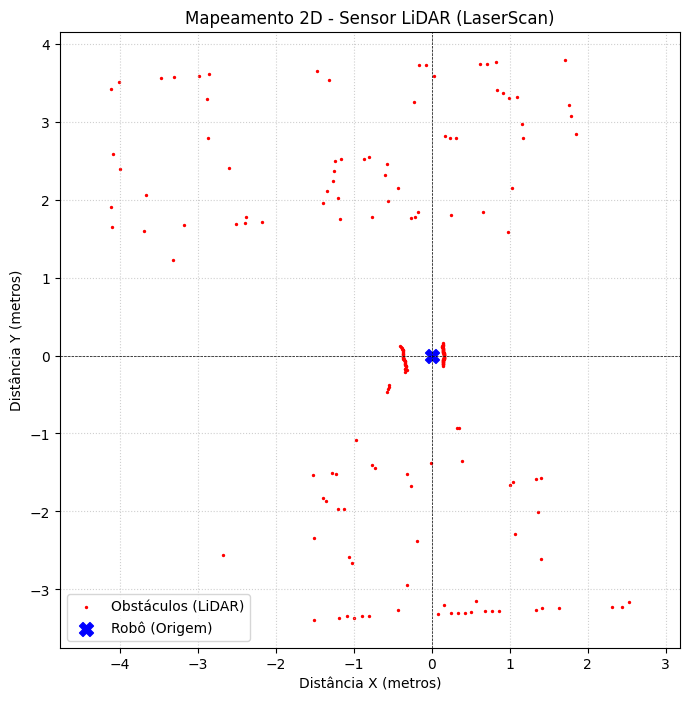

In [72]:
import math
import matplotlib.pyplot as plt

if 'ranges' not in scan_data or not scan_data['ranges']:
    print("Erro: scan_data está vazio. Aguarde mais tempo para o tópico receber dados.")
else:
    ranges = scan_data['ranges']
    angle_min = scan_data['angle_min']
    angle_increment = scan_data['angle_increment']

    x = []
    y = []

    # 2. Converter coordenadas polares para cartesianas
    for i, distance in enumerate(ranges):
        # PROTEÇÃO CONTRA ERROS DE TIPO (comum no roslibpy)
        # Se a leitura for None, texto ou inválida, nós ignoramos
        if distance is None or isinstance(distance, str):
            continue
            
        try:
            if math.isinf(distance) or math.isnan(distance) or distance <= 0:
                continue
        except TypeError:
            # Caso passe algum tipo estranho que o math não consiga ler
            continue
            
        # Calcular o ângulo atual da leitura atual
        angle = angle_min + (i * angle_increment)
        
        # Conversão trigonométrica
        x_pos = distance * math.cos(angle)
        y_pos = distance * math.sin(angle)
        
        x.append(x_pos)
        y.append(y_pos)

    # 3. Configurar e exibir o gráfico (Só plota se houver pontos válidos)
    if len(x) > 0:
        plt.figure(figsize=(8, 8))
        # Plota os pontos do obstáculo
        plt.scatter(x, y, c='red', s=2, label='Obstáculos (LiDAR)') 
        # Plota a posição do robô na origem (0,0)
        plt.scatter(0, 0, c='blue', marker='X', s=100, label='Robô (Origem)') 

        # Customização do gráfico
        plt.title('Mapeamento 2D - Sensor LiDAR (LaserScan)')
        plt.xlabel('Distância X (metros)')
        plt.ylabel('Distância Y (metros)')
        plt.axhline(0, color='black', linewidth=0.5, linestyle='--')
        plt.axvline(0, color='black', linewidth=0.5, linestyle='--')
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.legend()
        plt.axis('equal') 

        plt.show()
    else:
        print("Nenhum ponto válido encontrado no alcance do LiDAR para plotar.")


In [8]:
scan_data = {}

def callback_scan(msg):
    scan_data['ranges'] = msg['ranges']
    scan_data['angle_min'] = msg['angle_min']
    scan_data['angle_increment'] = msg['angle_increment']

scan = roslibpy.Topic(client, '/scan', 'sensor_msgs/LaserScan')
scan.subscribe(callback_scan)

time.sleep(1) # aguardar a primeira leitura chegar
print('Número de leituras:', len(scan_data['ranges']))
print('Distância à frente (índice 0):', scan_data['ranges'][0])
print('Distância à trás (índice 120):', scan_data['ranges'][120])

print('Angle min', scan_data['angle_min'])
print('Angle increment', scan_data['angle_increment'])

Número de leituras: 236
Distância à frente (índice 0): 2.989000082015991
Distância à trás (índice 120): 0.2709999978542328
Angle min 0.01086672954261303
Angle increment 0.026536570861935616


Tarefa

Distância à frente (índice 0): 3.316999912261963
Distância à trás (índice 0): 0.3540000021457672

Parte 2 - 2.6

In [14]:
import math

DISTANCIA_SEGURANCA = 0.4 # metros
VELOCIDADE_FRENTE = 0.2199
VELOCIDADE_GIRO = 1.0

def distancia_frontal():
    ranges = scan_data.get('ranges', [])
    if not ranges:
        return float('inf')
    # janela pequena em torno do índice frontal (ajuste conforme seu robô)
    frente = ranges[0:5] + ranges[-5:]
    #print(frente)
    frente = [d for d in frente if d is not None]
    validos = [d for d in frente if d > 0.0 and not math.isinf(d)]
    return min(validos) if validos else float('inf')

def desviar_obstaculos(tempo_total=30):
    inicio = time.time()
    while time.time() - inicio < tempo_total:
        d = distancia_frontal()
        if d < DISTANCIA_SEGURANCA:
            cmd_vel.publish(roslibpy.Message({
                'linear': {'x': 0.0, 'y': 0.0, 'z': 0.0},
                'angular': {'x': 0.0, 'y': 0.0, 'z': VELOCIDADE_GIRO}
            }))
        else:
            cmd_vel.publish(roslibpy.Message({
                'linear': {'x': VELOCIDADE_FRENTE, 'y': 0.0, 'z': 0.0},
                'angular': {'x': 0.0, 'y': 0.0, 'z': 0.0}
            }))
        time.sleep(0.1)
    parar()
    
desviar_obstaculos()

Parte 2.7

In [17]:
import math
import numpy

DISTANCIA_SEGURANCA = 0.4 # metros
VELOCIDADE_FRENTE = 0.21999
VELOCIDADE_GIRO = 1.5

def distancia_frontal():
    ranges = scan_data.get('ranges', [])
    if not ranges:
        return float('inf')
    # janela pequena em torno do índice frontal (ajuste conforme seu robô)
    frente = ranges[0:5] + ranges[-5:]
    frente = [d for d in frente if d is not None]
    validos = [d for d in frente if d > 0.0 and not math.isinf(d)]
    esquerda = numpy.array(frente[-5:])
    direita = numpy.array(frente[0:5])
    if esquerda.mean() < direita.mean():
        lado_certo = "d"
    else:
        lado_certo = "e"
    
    return (min(validos), lado_certo) if validos else (float('inf'), 0)

def desviar_obstaculos(tempo_total=30):
    inicio = time.time()
    while time.time() - inicio < tempo_total:
        d, l = distancia_frontal()
        if d < DISTANCIA_SEGURANCA and l == "e":
            cmd_vel.publish(roslibpy.Message({
                'linear': {'x': 0.0, 'y': 0.0, 'z': 0.0},
                'angular': {'x': 0.0, 'y': 0.0, 'z': -VELOCIDADE_GIRO}
            }))
        elif d < DISTANCIA_SEGURANCA and l == "d":
            cmd_vel.publish(roslibpy.Message({
                'linear': {'x': 0.0, 'y': 0.0, 'z': 0.0},
                'angular': {'x': 0.0, 'y': 0.0, 'z': VELOCIDADE_GIRO}
            }))
        else:
            cmd_vel.publish(roslibpy.Message({
                'linear': {'x': VELOCIDADE_FRENTE, 'y': 0.0, 'z': 0.0},
                'angular': {'x': 0.0, 'y': 0.0, 'z': 0.0}
            }))
        time.sleep(0.1)
    parar()
    
desviar_obstaculos()

Encerrar

In [19]:
#parar()
client.terminate()


AttributeError: 'TwistedEventLoopManager' object has no attribute '_thread'